In [1]:
import os
import yaml
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import glob

# Load the YAML configuration
yaml_path = "../datasets/DOOM_yolo_seg/vizdoom.yaml"
with open(yaml_path, 'r') as f:
    config = yaml.safe_load(f)

print("Dataset Configuration:")
print(f"Path: {config['path']}")
print(f"Train: {config['train']}")
print(f"Val: {config['val']}")
print(f"Number of classes: {config['nc']}")
print(f"Classes: {config['names']}")

FileNotFoundError: [Errno 2] No such file or directory: '../datasets/DOOM_yolo_seg/vizdoom.yaml'

In [10]:
# Check dataset structure
dataset_path = os.path.join(config['path'])
train_img_path = os.path.join(dataset_path, config['train'], "images")
val_img_path = os.path.join(dataset_path, config['val'], 'images')
train_label_path = os.path.join(dataset_path, config['train'], "labels")
val_label_path = os.path.join(dataset_path, config['val'], "labels")

print(f"\nChecking dataset structure:")
print(f"Train images: {len(glob.glob(os.path.join(train_img_path, '*.jpg')))} files")
print(f"Train labels: {len(glob.glob(os.path.join(train_label_path, '*.txt')))} files")
print(f"Val images: {len(glob.glob(os.path.join(val_img_path, '*.jpg')))} files")
print(f"Val labels: {len(glob.glob(os.path.join(val_label_path, '*.txt')))} files")


Checking dataset structure:
Train images: 3872 files
Train labels: 3872 files
Val images: 968 files
Val labels: 968 files



Training samples with annotations:


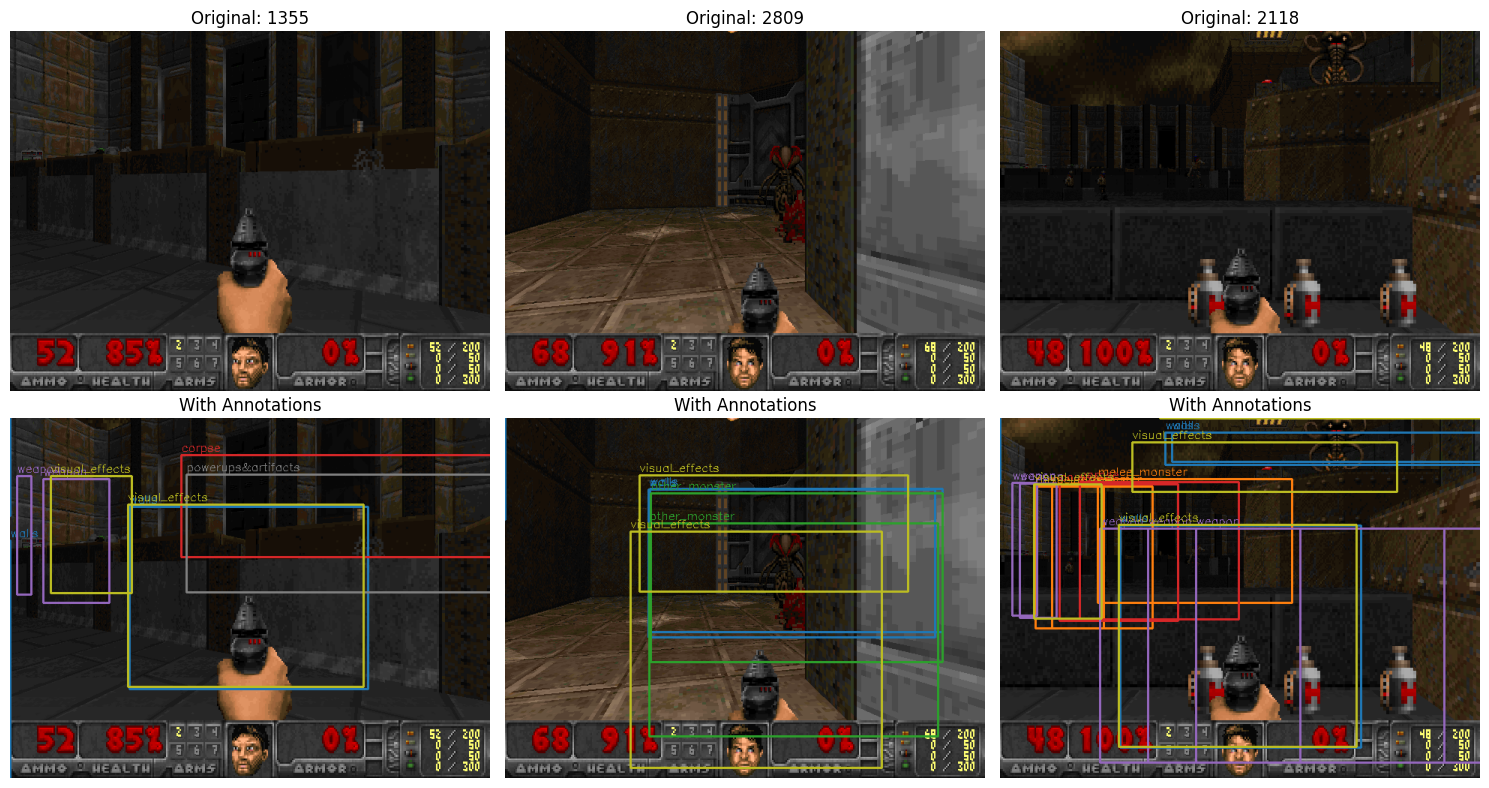

In [ ]:
def visualize_yolo_annotations(img_path, label_path, class_names, num_samples=5):
    """Visualize YOLO annotations on images"""
    img_files = glob.glob(os.path.join(img_path, "*.jpg"))[:num_samples]
    
    fig, axes = plt.subplots(2, len(img_files), figsize=(15, 8))
    if len(img_files) == 1:
        axes = axes.reshape(-1, 1)
    
    for i, img_file in enumerate(img_files):
        # Load image
        img = cv2.imread(img_file)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        
        # Load corresponding label
        base_name = os.path.splitext(os.path.basename(img_file))[0]
        label_file = os.path.join(label_path, f"{base_name}.txt")
        
        # Original image
        axes[0, i].imshow(img_rgb)
        axes[0, i].set_title(f"Original: {base_name}")
        axes[0, i].axis('off')
        
        # Image with annotations
        img_annotated = img_rgb.copy()
        
        if os.path.exists(label_file):
            with open(label_file, 'r') as f:
                lines = f.readlines()
            
            colors = plt.cm.tab10(np.linspace(0, 1, len(class_names)))
            
            for line in lines:
                parts = line.strip().split()
                if len(parts) >= 5:
                    class_id = int(parts[0])
                    x_center, y_center, width, height = map(float, parts[1:5])
                    
                    # Convert normalized coordinates to pixel coordinates
                    x_center *= w
                    y_center *= h
                    width *= w
                    height *= h
                    
                    # Calculate bounding box coordinates
                    x1 = int(x_center - width/2)
                    y1 = int(y_center - height/2)
                    x2 = int(x_center + width/2)
                    y2 = int(y_center + height/2)
                    
                    # Draw bounding box
                    color = (np.array(colors[class_id][:3]) * 255).astype(int)
                    cv2.rectangle(img_annotated, (x1, y1), (x2, y2), color.tolist(), 2)
                    
                    # Add class label
                    label_text = class_names[class_id] if class_id < len(class_names) else f"Class_{class_id}"
                    cv2.putText(img_annotated, label_text, (x1, y1-5), 
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, color.tolist(), 1)
        
        axes[1, i].imshow(img_annotated)
        axes[1, i].set_title(f"With Annotations")
        axes[1, i].axis('off')
    
    plt.tight_layout()
    plt.show()

# Visualize training samples
print("\nTraining samples with annotations:")
visualize_yolo_annotations(train_img_path, train_label_path, config['names'], 3)